
### Flood Frequency Analysis
#### using NFRA river data

Modelling river flow considering extreme events using extreme value theory.

We consider the Tummel at Pitlochry- a flood monitoring station.
https://nrfa.ceh.ac.uk/data/station/info/15012

API usage example at https://github.com/NERC-CEH/nrfa/blob/master/api/examples/python/basic_example.py

1. Daily flow distribution
- Histogram
- Show heavy right tail
2. Annual maxima extraction -> justify choice of block -> plot seasonality?
- Histogram of maxima
- Summary statistics
3. Stationarity checks
- Time series
- Rolling mean
- Augmented Dickey–Fuller test
4. GEV fitting
- Estimated parameters
- Histogram + fitted GEV density
5. Model validation
- QQ plot
- Return level plot
- PP/CDF plot
6. Risk estimates
-10-, 50-, 100-, and 500-year return levels
- Confidence intervals (via bootstrapping)

TO DO:
- bootstrap confidence intervals onto block maxima analysis
- peaks-over-thereshold with GPD for comparison (bootstrap also)

In [3]:
import urllib.request
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Matplotlib is building the font cache; this may take a moment.


In [4]:
# The base URL to access the NFRA API
base_url = "https://nrfaapps.ceh.ac.uk/nrfa/ws"

In [5]:
query = "format=json-object"
station_ids_url = "{BASE}/station-ids?{QUERY}".format(BASE=base_url,
                                                      QUERY=query)

### Inspect a river flow and exploratory data analysis

#### River location -> Pitlochry
I pick a personal favourite river spot that i know well...

#### View gauged daily flow (gdf)
The Gauged Daily Flow is the mean river flow in cubic metres per second, more information available here   
https://nrfa.ceh.ac.uk/data/about-data/daily-flow-data/gauged-daily-flow-data

In [7]:
query = "station=15012&data-type=gdf&format=json-object"
stations_info_url = "{BASE}/time-series?{QUERY}".format(BASE=base_url,
                                                        QUERY=query)

# Send request and read response
response = urllib.request.urlopen(stations_info_url).read()

# Decode from JSON to Python dictionary
response = json.loads(response)

# See data from response
print("3. Details of time series:")
print("Time of request: %s" % response["timestamp"])
print("Station: %s" % response['station']['name'])
print("Data type: %s" % response['data-type']['name'])
print("Data time series (first 10):")
print(response['data-stream'][:10])


3. Details of time series:
Time of request: 2026-07-10T15:47:42
Station: Tummel at Pitlochry
Data type: Gauged Daily Flow
Data time series (first 10):
['1973-01-01', 160, '1973-01-02', 148, '1973-01-03', 115.5, '1973-01-04', 109.6, '1973-01-05', 119.6]


In [8]:
gauged_daily_flow = response['data-stream']

In [9]:
date_idx = range(0,len(gauged_daily_flow),2)
data = pd.DataFrame({'Date':gauged_daily_flow[::2],'gdf':gauged_daily_flow[1::2]})
#dates = pd.Series(gauged_daily_flow[::2])
#gdfs = pd.Series(gauged_daily_flow[1::2])

print(data.head())

         Date    gdf
0  1973-01-01  160.0
1  1973-01-02  148.0
2  1973-01-03  115.5
3  1973-01-04  109.6
4  1973-01-05  119.6


We can see for each date we have a single number in our dataframe - the gauged daily flow.
It looks like there is one gdf for each date, but we shall check.

#### Data quality checks

In [11]:
data['Date'] = pd.to_datetime(data['Date'])

In [12]:
# check empty cells in dataframe
assert not data['Date'].isna().any(), "Missing values in date column"
assert not data['gdf'].isna().any(), "Missing values in gdf column"

# check dates not skipped
expected_days = (data['Date'].max() - data['Date'].min()).days + 1
actual_days = data.shape[0]
assert expected_days - actual_days == 0, "Dates missing"

# check duplicates
assert not data["Date"].duplicated().any(), "Duplicate dates detected"

# check sorted by date
assert data["Date"].is_monotonic_increasing, "Dates are not sorted"

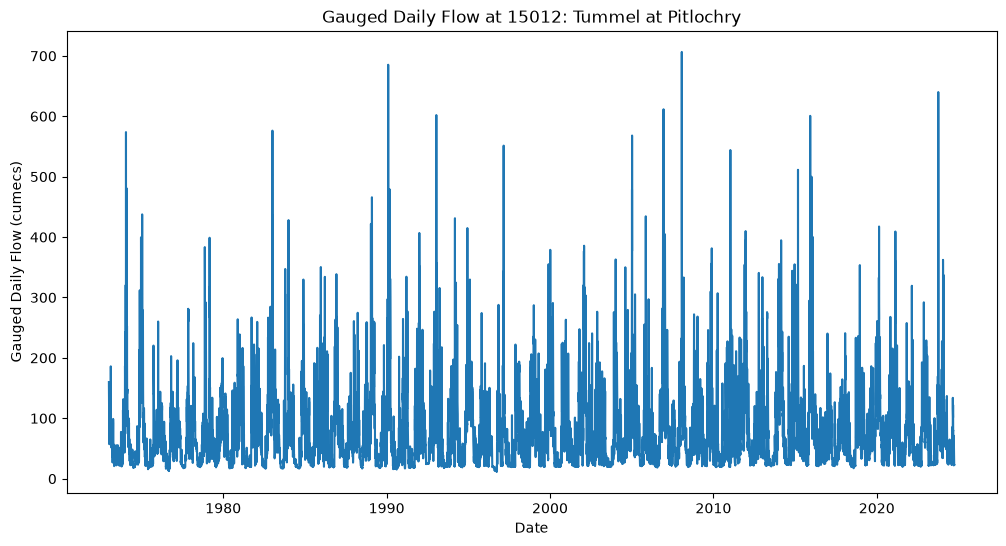

In [13]:
fig,ax = plt.subplots(figsize=(12,6))

plt.title('Gauged Daily Flow at 15012: Tummel at Pitlochry')
plt.ylabel('Gauged Daily Flow (cumecs)')
plt.xlabel('Date')
ax.plot(data['Date'],data['gdf'])
plt.show()
                              

So above you can see the plot for gauged daily flow at one specific station location in Pitlochry. This may be more interpretable if we look at a histogram of this data, which will give us an idea of the distribution of the data.

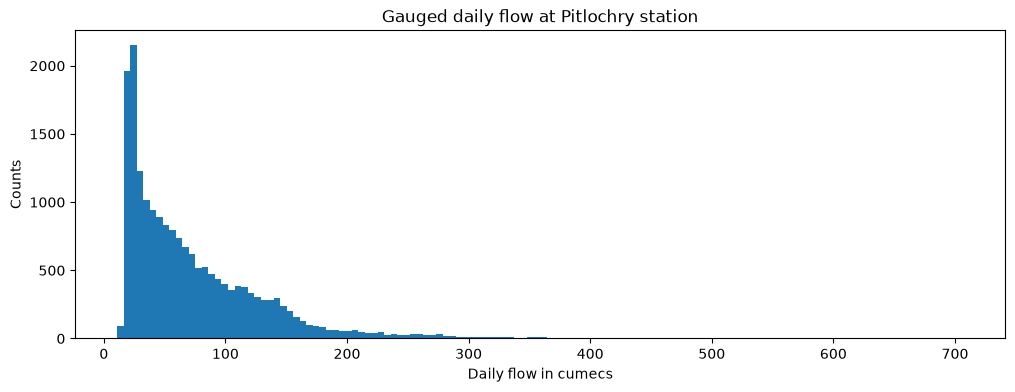

In [15]:
fig,ax = plt.subplots(figsize=(12,4))

# determine number of bins using Freedman-Diaconis rule
ax.hist(data['gdf'], bins='fd')
plt.title("Gauged daily flow at Pitlochry station")
plt.ylabel("Counts")
plt.xlabel("Daily flow in cumecs")
plt.show()

We can see the distribution is heavily right-skewed, with a mode of around 25 cumecs. It will be worth putting some figures on what we can see above.

In [17]:
summary = pd.DataFrame(
    {"Statistic":
     ["Number of observations", "Mean daily flow", "Median daily flow"," Standard deviation","Skewness","99th percentile"],
     "Value":
     [len(data), data['gdf'].mean(), data['gdf'].median(),data['gdf'].std(),data['gdf'].skew(),data['gdf'].quantile(0.99)]})

summary.style.format({
    "Value": "{:.2f}"
})

,Statistic,Value
0,Number of observations,18901.00
1,Mean daily flow,74.51
2,Median daily flow,56.10
3,Standard deviation,61.38
4,Skewness,2.34
5,99th percentile,301.00


We see a skewness > 1 indicating the distribution is heavily right skewed. The mean flow exceeds the median flow, indicating that a small number of high-flow events influence the distribution, meaning the median may be a better measure of central tendency. The upper 1% of observations are substantially larger than typical daily flows, demonstrating the presence of extreme events.

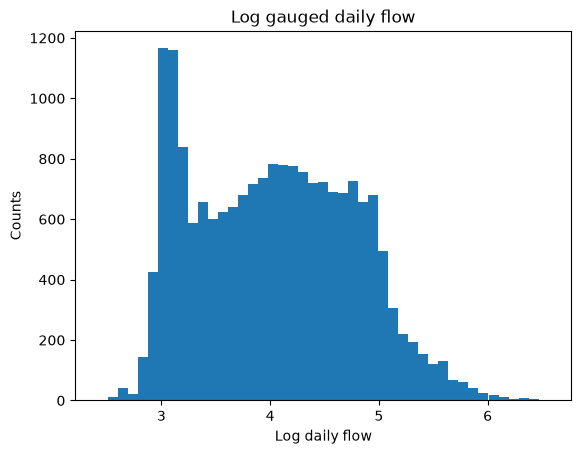

In [19]:
plt.hist(np.log(data["gdf"]), bins="fd")
plt.ylabel("Counts")
plt.xlabel("Log daily flow")
plt.title("Log gauged daily flow")

plt.show()

This looks closer to a normal distribution, but still has a large number of counts around log 3-log 3.2 (20-25), as per the peak with a non-log scale. Overall we see a heavy right-skewed distribution that also can not be described well by a log normal distribution.
However in flood risk analysis, we are interested in the tail events of a distribution, where extreme value methods come in.

### Applying extreme value methods

Extreme value theory provides us with a framework to model extreme events by characterising the tail behaviour of a distribution, where standard statistical models based on the bulk of the data are likely to be inadequate. The extreme value distributions form a model by focusing on the statistical behaviour of the maximum (or minimums) of samples from a random variable. Errors in estimating tail behaviour using standard statistical techniques can become substantial when extrapolating to rare events.

To model the maximums of samples from our distribution of gauged daily flows we can the generalised extreme value (GEV) family of distributions. The GEV unifies the Gumbel, Fréchet, and Weibull distributions into a single model, allowing the most appropriate distribution for the data to be identified.

### Analyse block maxima

One way to model the tail of our daily flow is through block maxima. We define a blocks of the data of equal length. A reasonable assumption might be to choose a year as a block due to the seasonality of the climate.


In [23]:
### add seasonality plot

#### Consider annual maxima

In [25]:
yearly_max = data.groupby(data['Date'].dt.year)['gdf'].max()
years = np.unique(data['Date'].dt.year)

In [26]:
annual_max = pd.DataFrame({'Year':years,'Yearly Max':yearly_max})

In [27]:
first_year,last_year = annual_max['Year'].min(),annual_max['Year'].max()
print(first_year,last_year)

1973 2024


So we have years 1973-2024 inclusive, so 52 years of values for our block maxima.

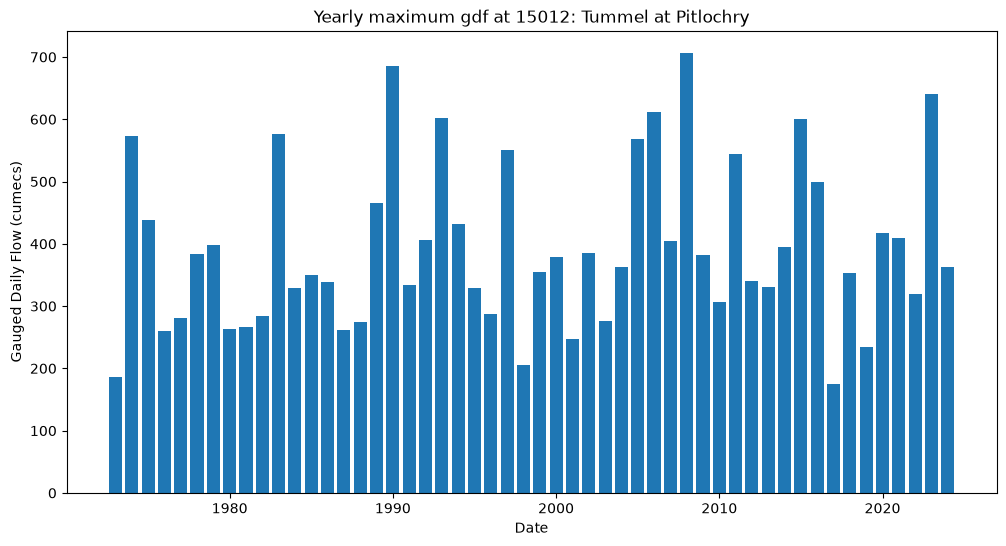

In [29]:
fig,ax = plt.subplots(figsize=(12,6))

plt.title('Yearly maximum gdf at 15012: Tummel at Pitlochry')
plt.ylabel('Gauged Daily Flow (cumecs)')
plt.xlabel('Date')
ax.bar(years,yearly_max)
plt.show()

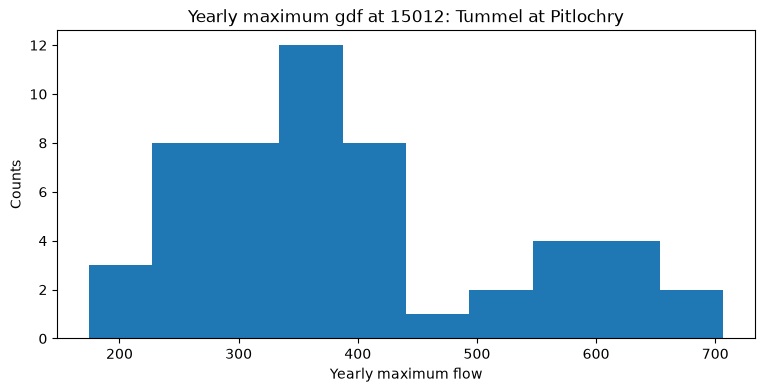

In [30]:
fig,ax = plt.subplots(figsize=(9,4))

plt.title('Yearly maximum gdf at 15012: Tummel at Pitlochry')
plt.ylabel('Counts')
plt.xlabel('Yearly maximum flow')
ax.hist(yearly_max)
plt.show()

### Analyse trends / stationarity

Before applying our GEV model, we want to consider the stationarity of the annual maxima, since the standard GEV model assumes the distribution of extremes is constant over time. To do this we can look at the moving average. 

#### Consider moving average of max yearly flows

In [32]:
def moving_average(x, w):
    return np.convolve(x, np.ones(w), 'valid') / w

In [33]:
w = 10 # window size to average over, use 10-20% of sample size
mov_avg = moving_average(yearly_max,w)

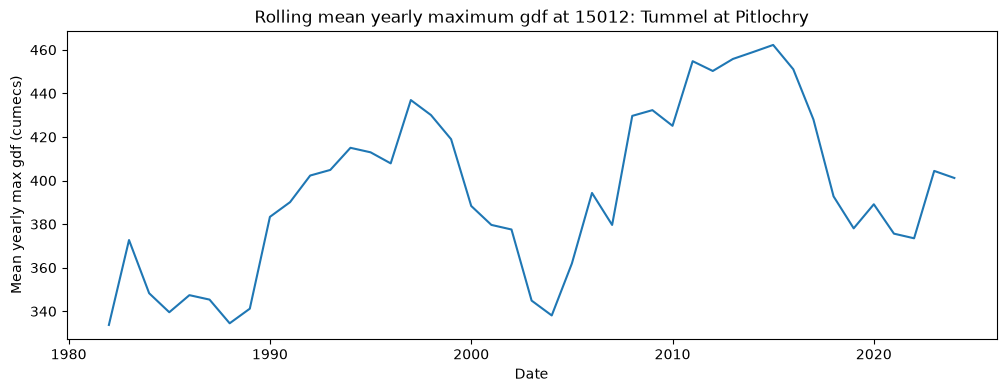

In [34]:
fig,ax = plt.subplots(figsize=(12,4))

plt.title('Rolling mean yearly maximum gdf at 15012: Tummel at Pitlochry')
plt.ylabel('Mean yearly max gdf (cumecs)')
plt.xlabel('Date')
ax.plot(years[w-1:],mov_avg)
plt.show()

#### Augmented Dicker Fuller test

In [36]:
from statsmodels.tsa.stattools import adfuller
# ADF Test
result = adfuller(yearly_max, autolag='AIC')
print(f'ADF Statistic: {result[0]}')
print(f'n_lags: {result[1]}')
print(f'p-value: {result[1]}')
for key, value in result[4].items():
    print('Critial Values:')
    print(f'   {key}, {value}')   

ADF Statistic: -7.274517767966025
n_lags: 1.557014257896414e-10
p-value: 1.557014257896414e-10
Critial Values:
   1%, -3.5656240522121956
Critial Values:
   5%, -2.920142229157715
Critial Values:
   10%, -2.598014675124952


The results of the augmented dickey-fuller test suggest we can not reject the hypothesis of a unit root

#### Consider largest 5 order statistics per year

In [39]:
yearly_t5 = data.groupby(data['Date'].dt.year)['gdf'].nlargest(5)

In [40]:
yearly_t5.index = yearly_t5.index.get_level_values(0)
print(yearly_t5)

Date
1973    186.6
1973    186.0
1973    184.7
1973    160.0
1973    157.2
        ...  
2024    362.3
2024    337.0
2024    308.0
2024    276.1
2024    263.1
Name: gdf, Length: 260, dtype: float64


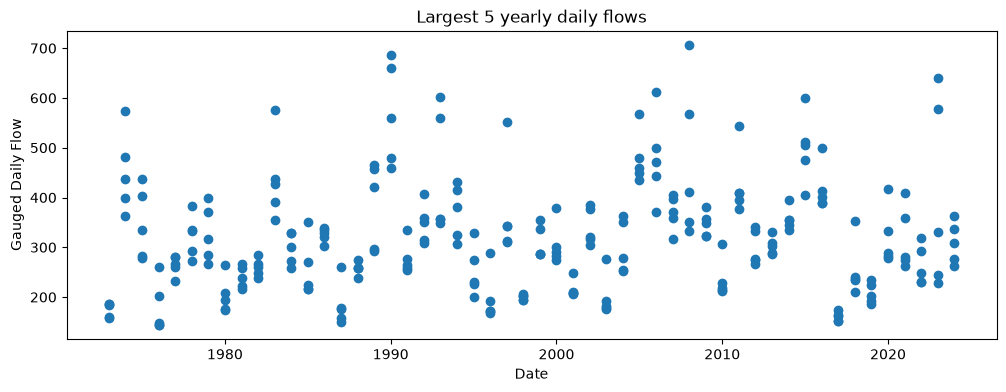

In [41]:
fig,ax = plt.subplots(figsize=(12,4))

plt.title('Largest 5 yearly daily flows')
plt.ylabel('Gauged Daily Flow')
plt.xlabel('Date')
ax.scatter(yearly_t5.index,yearly_t5.values)
plt.show()

Visually it doesn't look like a trend exists if we consider top 5 order statistics.

Back to annual max daily flows. We will rank the annual maxes.

In [43]:
annual_max['Rank'] = annual_max['Yearly Max'].rank()
print(annual_max.shape)
print(annual_max.head())

(52, 3)
      Year  Yearly Max  Rank
Date                        
1973  1973       186.6   2.0
1974  1974       573.8  45.0
1975  1975       437.6  39.0
1976  1976       260.2   6.0
1977  1977       281.3  12.0


#### Exceedance Probabilities and Return Periods

We can use observed data to estimate exceedance probablities using ranked observations- an empirical approach.

A naive estimator of exceedance probabilities is  $ P(X > x_{(i)}) = \frac{n-i}{n} $,  
where n is the sample size and i is the rank of the observation when data are sorted from smallest to largest.

However, this estimator has a known issue in the upper tail: the maximum observation is assigned an exceedance probability of 0, which is unrealistic since it incorrectly implies that larger values are impossible.
To address this, we use plotting position formulas, such as the Gringorten formula, which provide a better estimate of tail probabilities:

$ \hat{F}(x_{(i)}) = \frac{i-a}{N + 1 -2a} $  

$\hat{F}(x_{(i)})$ = non exceedance probability.

N = Number of observations in your record.

i = Rank of specific observation (smallest to largest)

a = constant for estimation = 0.44


In [45]:
annual_max['NEP'] = (annual_max['Rank'] - 0.44) / (annual_max.shape[0] + 1 - (2*0.44))
annual_max['EP'] = 1 - annual_max['NEP']
annual_max['Return Period'] = 1/ (annual_max['EP'])

In [46]:
annual_max.head()

,Year,Yearly Max,Rank,NEP,EP,Return Period
Date,,,,,,
1973,1973,186.6,2.0,0.029931,0.970069,1.030854
1974,1974,573.8,45.0,0.854950,0.145050,6.894180
1975,1975,437.6,39.0,0.739831,0.260169,3.843658
1976,1976,260.2,6.0,0.106677,0.893323,1.119416
1977,1977,281.3,12.0,0.221796,0.778204,1.285010


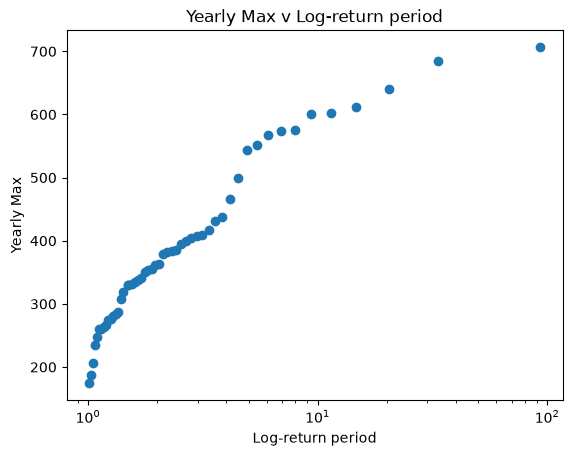

In [47]:
plt.scatter(annual_max['Return Period'], annual_max['Yearly Max'])
plt.xscale('log')
plt.xlabel("Log-return period")
plt.ylabel("Yearly Max")
plt.title("Yearly Max v Log-return period")
plt.show()

#### Fit and plot GEV distributions

Plot a QQ-plot against a Gumbel for the block maxima values, since Gumbel has ξ = 0, we can see if it has lighter tails falling closer to a Weibull (ξ < 0) or heavier tails, Frechet (ξ > 0).

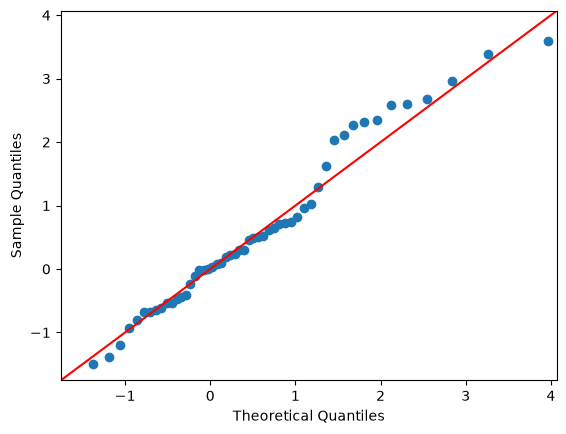

In [49]:
import statsmodels.api as sm
from scipy import stats

x = annual_max['Yearly Max'].values

sm.qqplot(x, dist=stats.gumbel_r, fit=True, line='45')
plt.show()

Fit the generalised extreme value distribution to find  ξ.

In [51]:
from scipy.stats import genextreme

c, loc, scale = genextreme.fit(x)

print(c, loc, scale)

0.01600584110270862 332.0876425691654 104.99566569270158


From the above we can see  ξ is 0.016, close to 0 so close to a Gumbel distribution.
We can compare the GEV fit to the Gumbel fit below.

In [53]:
from scipy.stats import genextreme, gumbel_r

# GEV fit
c, loc_gev, scale_gev = genextreme.fit(x)

# Gumbel fit
loc_g, scale_g = gumbel_r.fit(x)

for p in [0.9, 0.98, 0.99]:
    gev = genextreme.ppf(p, c, loc=loc_gev, scale=scale_gev)
    gum = gumbel_r.ppf(p, loc=loc_g, scale=scale_g)

    print(f"p={p}:")
    print("  GEV   =", gev)
    print("  Gumbel=", gum)

p=0.9:
  GEV   = 564.1618256530328
  Gumbel= 566.1937428581025
p=0.98:
  GEV   = 729.2432654942452
  Gumbel= 738.6598628311942
p=0.99:
  GEV   = 797.73055633888
  Gumbel= 811.5708328264876
